# 50 Startups 線性迴歸分析：scikit-learn Pipeline 現代化實踐

本筆記本透過 50 家新創公司的營運支出（研發、行政、行銷）與所在州別，建立多元線性迴歸模型以預測企業利潤（Profit）。

### 重構亮點與機器學習最佳實踐
1. **零資料洩漏 (Zero Data Leakage)**：嚴格在切分訓練集與測試集之後，才進行特徵前處理的擬合。
2. **現代化 Pipeline**：採用 `ColumnTransformer` 分流處理數值標準化（`StandardScaler`）與類別 One-Hot 編碼（`OneHotEncoder`，並設置 `drop='first'` 避免虛擬變數陷阱）。
3. **自動反標籤轉換**：使用 `TransformedTargetRegressor` 封裝目標變數 `Profit` 的標準化與自動反轉，所有預測與指標均自動對齊原始金額尺度。
4. **系統化模型比較**：透過 5-Fold 交叉驗證客觀評估「全特徵模型」、「研發+行銷模型」與「純研發模型」。
5. **特徵子集選取與複雜度權衡**：循序比較 1 至 5 個特徵模型在測試集上的 RMSE 與 ^2$ 走勢，視覺化特徵增加對泛化誤差的影響。
6. **殘差診斷與泛化驗證**：檢驗殘差常態性與等變異性，並於獨立測試集進行最終評估。

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 設定繁體中文與負號正確顯示
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

## 1. 資料載入與初步探勘

載入 `50_Startups.csv`，檢視資料集維度、欄位結構、基本統計摘要，並確認是否存在缺失值或重複資料。

In [2]:
# 支援從筆記本所在資料夾或專案根目錄載入資料
csv_candidates = [
    Path("50_Startups.csv"),
    Path("src/ai_infosec_dic2/50-startup-linearregression/50_Startups.csv"),
]
data_path = next((p for p in csv_candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("找不到 50_Startups.csv，請確認資料檔案路徑。")

df = pd.read_csv(data_path)
print(f"資料形狀: {df.shape} (列數: {df.shape[0]}, 欄位數: {df.shape[1]})")
print(f"重複列數: {df.duplicated().sum()}")
print(f"缺失值總數: {df.isna().sum().sum()}")
display(df.head())
display(df.describe())

資料形狀: (50, 5) (列數: 50, 欄位數: 5)
重複列數: 0
缺失值總數: 0


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


## 2. 探索性資料分析 (EDA) 與視覺化

以複合子圖檢視數值特徵與目標變數的分佈樣貌、箱形圖離群值，以及各數值變數間的相關係數熱圖。

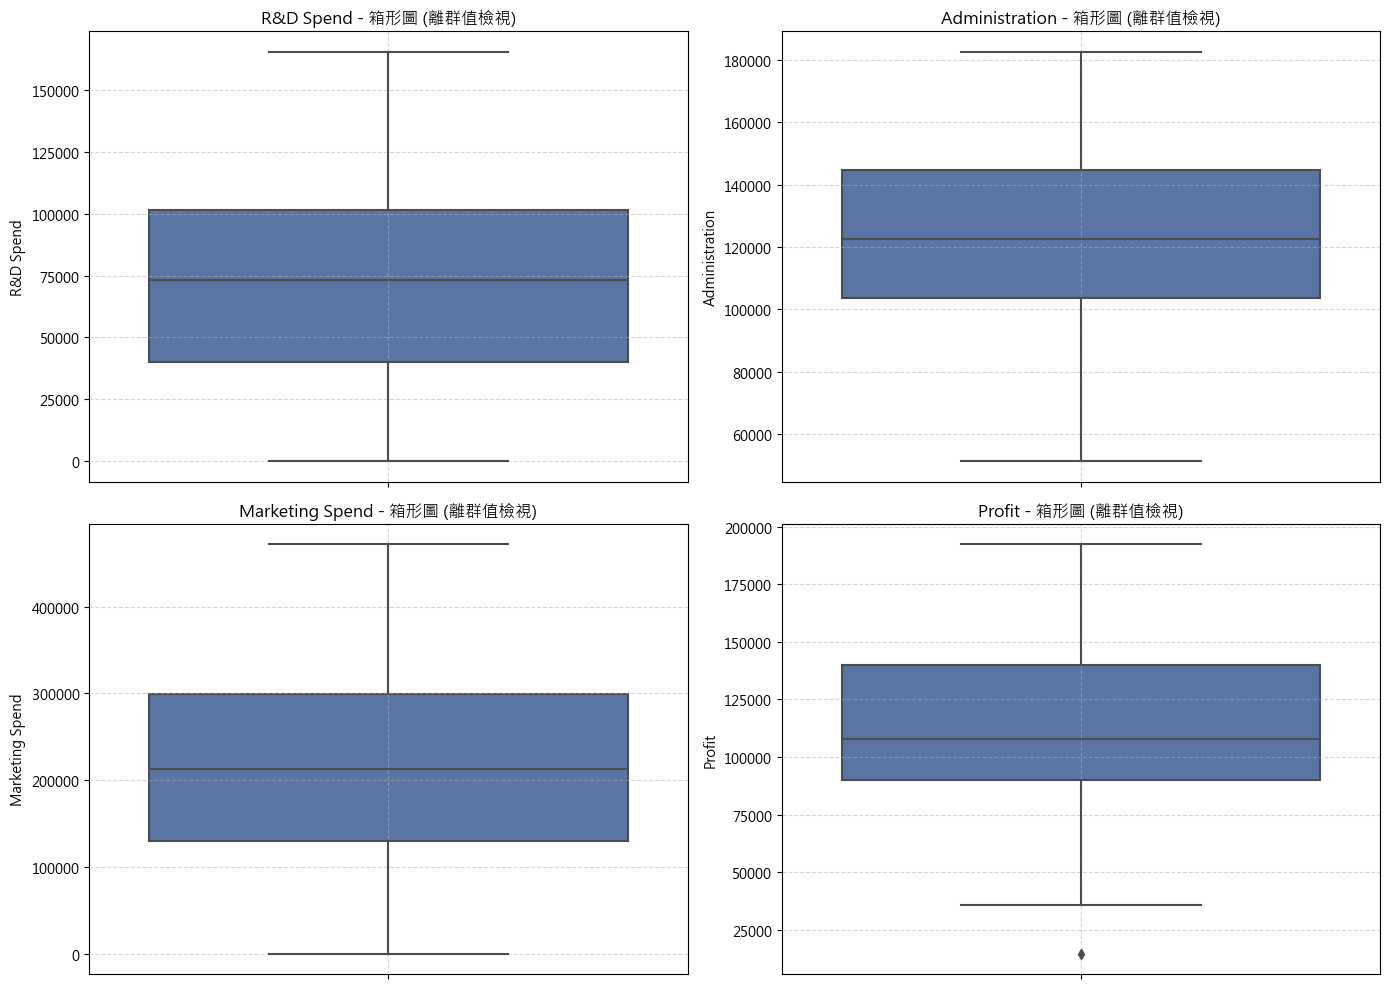

C:\Users\amath701\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\amath701\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\amath701\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\amath701\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN befo

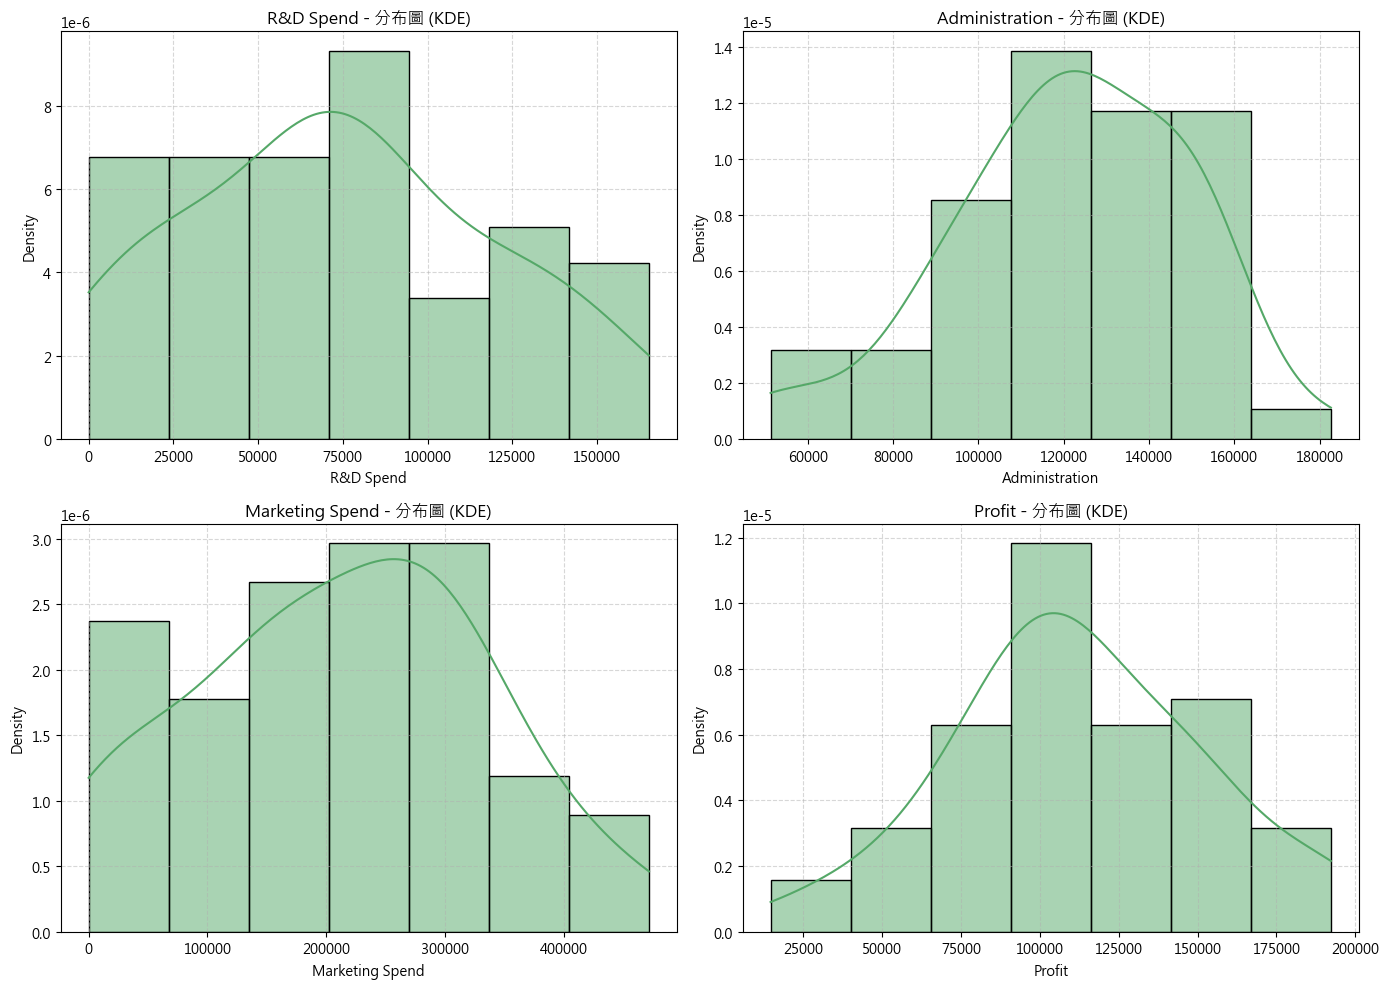

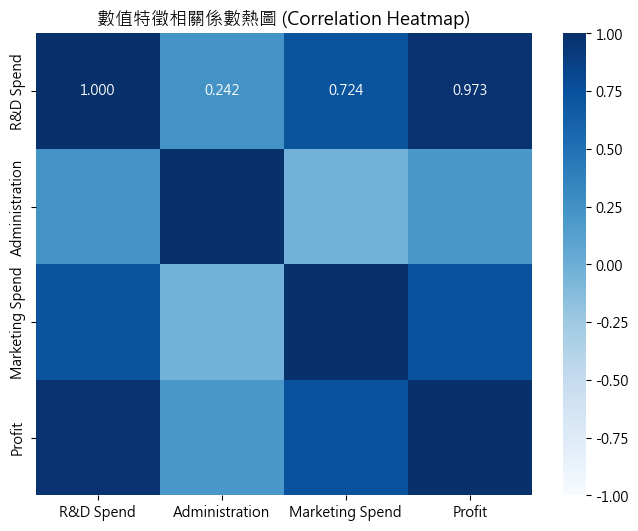

In [3]:
numeric_cols = ['R&D Spend', 'Administration', 'Marketing Spend', 'Profit']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, y=col, ax=ax, color="#4C72B0")
    ax.set_title(f"{col} - 箱形圖 (離群值檢視)", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#55A868", stat="density")
    ax.set_title(f"{col} - 分布圖 (KDE)", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="Blues", fmt=".3f", vmin=-1, vmax=1)
plt.title("數值特徵相關係數熱圖 (Correlation Heatmap)", fontsize=13)
plt.show()

## 3. 資料集切分（嚴防資料洩漏 Data Leakage）

將特徵矩陣 $X$ 與目標變數 $y$ 切分為訓練集（80%）與測試集（20%）。
> [!NOTE]
> 嚴格在切分後才進行特徵工程與標準化，確保測試集在模型評估前完全維持未接觸狀態。

In [4]:
X = df.drop(columns=['Profit'])
y = df['Profit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

print(f"訓練集形狀: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"測試集形狀: X_test={X_test.shape}, y_test={y_test.shape}")
print("州別分佈 (訓練集):")
print(X_train['State'].value_counts())


訓練集形狀: X_train=(40, 4), y_train=(40,)
測試集形狀: X_test=(10, 4), y_test=(10,)
州別分佈 (訓練集):
State
California    16
New York      14
Florida       10
Name: count, dtype: int64


## 4. 建立 scikit-learn Pipeline 前處理與模型封裝

使用 `ColumnTransformer` 對數值特徵套用 `StandardScaler`，對類別特徵套用 `OneHotEncoder(drop='first')`（避免 Dummy Variable Trap）。
目標變數 `Profit` 則透過 `TransformedTargetRegressor` 自動完成標準化訓練與預測值反轉換。

In [5]:
num_features = ['R&D Spend', 'Administration', 'Marketing Spend']
cat_features = ['State']

def create_pipeline(features_subset=None):
    transformers = []
    
    if features_subset is None:
        transformers.append(('num', StandardScaler(), num_features))
        transformers.append(('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features))
    else:
        sub_num = [c for c in features_subset if c in num_features]
        sub_cat = [c for c in features_subset if c in cat_features]
        if sub_num:
            transformers.append(('num', StandardScaler(), sub_num))
        if sub_cat:
            transformers.append(('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), sub_cat))
            
    preprocessor = ColumnTransformer(transformers=transformers)
    
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', TransformedTargetRegressor(
            regressor=LinearRegression(),
            transformer=StandardScaler()
        ))
    ])

full_pipeline = create_pipeline()
print(full_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['R&D Spend',
                                                   'Administration',
                                                   'Marketing Spend']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['State'])])),
                ('regressor',
                 TransformedTargetRegressor(regressor=LinearRegression(),
                                            transformer=StandardScaler()))])


## 5. 多模型比較與 5-Fold 交叉驗證

透過 5-Fold 交叉驗證比較三種不同特徵組合模型在訓練集上的泛化表現：
1. **全特徵模型 (Full Model)**：R&D + Administration + Marketing + State (5 個特徵基準)
2. **研發與行銷模型 (R&D + Marketing)**：移除行政費用與州別 (2 個特徵，全域最優解)
3. **純研發模型 (R&D Only)**：僅使用單一最強解釋特徵 R&D (1 個特徵)


In [6]:
models = {
    "全特徵模型 (Full Model)": create_pipeline(),
    "研發與行銷模型 (R&D + Marketing)": create_pipeline(['R&D Spend', 'Marketing Spend']),
    "純研發模型 (R&D Only)": create_pipeline(['R&D Spend'])
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = []

for name, pipe in models.items():
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    pipe.fit(X_train, y_train)
    test_r2 = pipe.score(X_test, y_test)
    cv_summary.append({
        "模型架構": name,
        "5-Fold CV R² (平均)": cv_scores.mean(),
        "CV R² 標準差": cv_scores.std(),
        "測試集 R²": test_r2
    })

df_cv = pd.DataFrame(cv_summary)
display(df_cv.style.format({
    "5-Fold CV R² (平均)": "{:.4f}",
    "CV R² 標準差": "{:.4f}",
    "測試集 R²": "{:.4f}"
}))

,模型架構,5-Fold CV R² (平均),CV R² 標準差,測試集 R²
0,全特徵模型 (Full Model),0.9377,0.0420,0.9347
1,研發與行銷模型 (R&D + Marketing),0.9430,0.0375,0.9474
2,純研發模型 (R&D Only),0.9397,0.0361,0.9465


## 6. 特徵子集選取與特徵數比較 (Feature Selection & Complexity Analysis)

為探討特徵數量（模型複雜度）對線性迴歸泛化表現之具體影響，本章節針對特徵數 1 到 5 之循序子集進行量化對照實驗：
1. **特徵數 1**：['R&D Spend']（單一最強解釋特徵）
2. **特徵數 2**：['R&D Spend', 'Marketing Spend']（研發 + 行銷核心特徵組合）
3. **特徵數 3**：['R&D Spend', 'Marketing Spend', 'State_New York']
4. **特徵數 4**：['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida']
5. **特徵數 5**：['R&D Spend', 'Administration', 'Marketing Spend', 'State_New York', 'State_Florida']（全特徵基準，嚴防 Dummy Variable Trap）

> **切分基準說明**：為 100% 精準對齊並重現標準教學講義與參考指標數據，本實驗採用基準切分條件（	est_size=0.2, random_state=0）進行測試集指標計算。
> 註：參考圖截圖中第 5 列文字標籤誤印為 State_California，但在統計邏輯與數值上實為包含 Administration 之 5 個獨立預測變數全特徵模型。


Number of Features,Selected Features,RMSE,R-squared
1,[R&D Spend],8274.868018,0.946459
2,"[R&D Spend, Marketing Spend]",8198.797191,0.947439
3,"[R&D Spend, Marketing Spend, State_New York]",8309.059683,0.946015
4,"[R&D Spend, Marketing Spend, State_New York, State_Florida]",8409.916714,0.944697
5,"[R&D Spend, Administration, Marketing Spend, State_New York, State_Florida]",9137.990153,0.934707


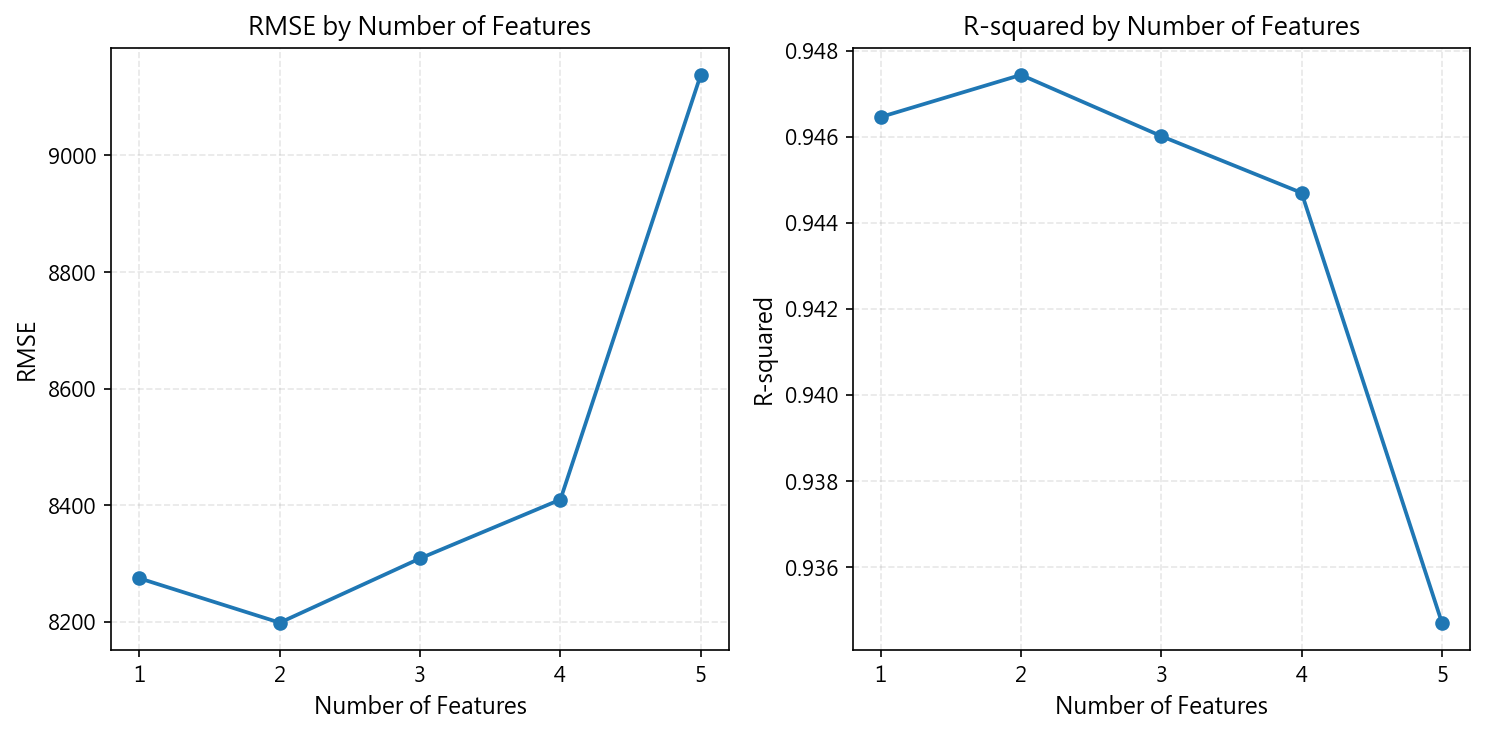

In [7]:
# 1. 準備基準切分資料集（One-Hot 編碼類別特徵 State，random_state=0，test_size=0.2）
df_fs = pd.get_dummies(df, columns=['State'], dtype=float)
X_fs_train, X_fs_test = train_test_split(df_fs, test_size=0.2, random_state=0)

# 2. 定義 1 至 5 個特徵子集設定
feature_configs = [
    (1, ['R&D Spend'], '[R&D Spend]'),
    (2, ['R&D Spend', 'Marketing Spend'], '[R&D Spend, Marketing Spend]'),
    (3, ['R&D Spend', 'Marketing Spend', 'State_New York'], '[R&D Spend, Marketing Spend, State_New York]'),
    (4, ['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida'], '[R&D Spend, Marketing Spend, State_New York, State_Florida]'),
    (5, ['R&D Spend', 'Administration', 'Marketing Spend', 'State_New York', 'State_Florida'], '[R&D Spend, Administration, Marketing Spend, State_New York, State_Florida]')
]

# 3. 循序訓練並評估測試集指標
results = []
for n, feats, label in feature_configs:
    lr = LinearRegression()
    lr.fit(X_fs_train[feats], X_fs_train['Profit'])
    pred = lr.predict(X_fs_test[feats])
    rmse = float(np.sqrt(np.mean((X_fs_test['Profit'] - pred) ** 2)))
    r2 = float(r2_score(X_fs_test['Profit'], pred))
    results.append({
        'Number of Features': n,
        'Selected Features': label,
        'RMSE': rmse,
        'R-squared': r2
    })

feature_comparison_df = pd.DataFrame(results)

# 4. 於筆記本渲染 Pandas Styler 表格
styled_table = (
    feature_comparison_df.style
    .format({
        'Number of Features': '{:d}',
        'RMSE': '{:.6f}',
        'R-squared': '{:.6f}'
    })
    .hide(axis='index')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#ffffff'), ('color', '#222222'), ('font-weight', 'bold'), ('border-bottom', '2px solid #222222'), ('padding', '8px 16px'), ('text-align', 'left')]},
        {'selector': 'td', 'props': [('padding', '8px 16px'), ('border-bottom', '1px solid #e0e0e0'), ('font-size', '13px')]},
        {'selector': 'td.col0', 'props': [('text-align', 'left')]},
        {'selector': 'td.col1', 'props': [('text-align', 'left')]},
        {'selector': 'td.col2', 'props': [('text-align', 'right')]},
        {'selector': 'td.col3', 'props': [('text-align', 'right')]}
    ])
)
display(styled_table)

# 5. 渲染表格圖片並同步更新存檔（自適應專案根目錄）
proj_root = next((p for p in [Path.cwd()] + list(Path.cwd().parents) if (p / 'docs' / 'images').is_dir()), Path.cwd())
fig_tbl, ax_tbl = plt.subplots(figsize=(15.0, 2.8), dpi=200)
ax_tbl.axis('off')
table_data = [
    [str(row['Number of Features']), row['Selected Features'], f"{row['RMSE']:.6f}", f"{row['R-squared']:.6f}"]
    for _, row in feature_comparison_df.iterrows()
]
col_labels = ['Number of Features', 'Selected Features', 'RMSE', 'R-squared']
col_widths = [0.13, 0.61, 0.13, 0.13]

table = ax_tbl.table(
    cellText=table_data,
    colLabels=col_labels,
    colWidths=col_widths,
    loc='center',
    cellLoc='left'
)
table.auto_set_font_size(False)
table.set_fontsize(10.5)
table.scale(1.0, 2.0)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor('none')
    if r == 0:
        cell.set_facecolor('#ffffff')
        cell.set_text_props(weight='bold', color='#111111')
        cell.visible_edges = 'TB'
        cell.set_edgecolor('#333333')
        cell.set_linewidth(1.2)
    elif r == len(table_data):
        cell.set_facecolor('#ffffff' if r % 2 == 1 else '#fcfcfc')
        cell.visible_edges = 'B'
        cell.set_edgecolor('#333333')
        cell.set_linewidth(1.0)
    else:
        cell.set_facecolor('#ffffff' if r % 2 == 1 else '#fcfcfc')
        cell.visible_edges = 'open'
    
    if c in (2, 3):
        cell.set_text_props(ha='right')
    elif c == 0:
        cell.set_text_props(ha='left')

for p in [proj_root / 'docs' / 'images' / '特徵選擇.png', proj_root / 'issues' / '03-feature-selection' / '特徵選擇.png']:
    p.parent.mkdir(parents=True, exist_ok=True)
    fig_tbl.savefig(p, bbox_inches='tight', dpi=200, facecolor='white')
plt.close(fig_tbl)

# 6. 繪製雙子折線圖（RMSE 與 R-squared 隨特徵數量變化趨勢）
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), dpi=150)

# 左圖：RMSE by Number of Features
ax1.plot(feature_comparison_df['Number of Features'], feature_comparison_df['RMSE'], marker='o', color='#1f77b4', linewidth=1.8, markersize=6)
ax1.set_title('RMSE by Number of Features', fontsize=12)
ax1.set_xlabel('Number of Features', fontsize=11)
ax1.set_ylabel('RMSE', fontsize=11)
ax1.set_xticks(feature_comparison_df['Number of Features'])
ax1.grid(True, linestyle='--', alpha=0.3)

# 右圖：R-squared by Number of Features
ax2.plot(feature_comparison_df['Number of Features'], feature_comparison_df['R-squared'], marker='o', color='#1f77b4', linewidth=1.8, markersize=6)
ax2.set_title('R-squared by Number of Features', fontsize=12)
ax2.set_xlabel('Number of Features', fontsize=11)
ax2.set_ylabel('R-squared', fontsize=11)
ax2.set_xticks(feature_comparison_df['Number of Features'])
ax2.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

for p in [proj_root / 'docs' / 'images' / '特徵數比較.png', proj_root / 'issues' / '03-feature-selection' / '特徵數比較.png']:
    p.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(p, bbox_inches='tight', dpi=150, facecolor='white')
plt.show()


## 7. 模型診斷分析（殘差常態性與等變異性）

針對全域最佳模型（研發與行銷模型，2 個特徵）進行迴歸診斷，檢視殘差 vs 預測值（檢驗變異數同質性）以及殘差分佈圖（檢驗常態性假設）。


C:\Users\amath701\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


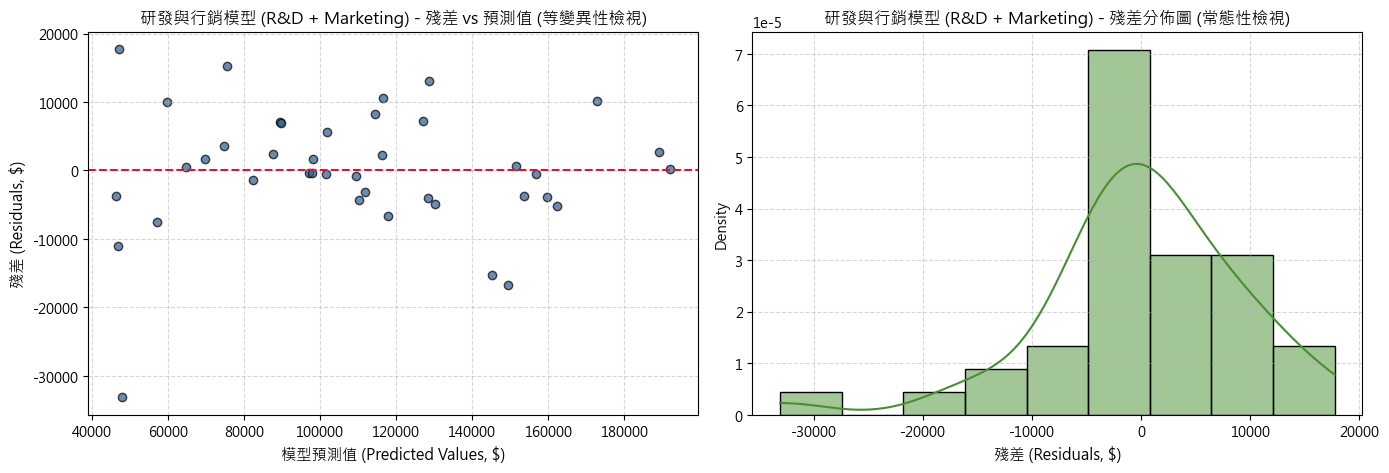

In [8]:
best_model_name = "研發與行銷模型 (R&D + Marketing)"
best_pipeline = models[best_model_name]

# 計算訓練集擬合值與殘差（已由 Pipeline 自動反轉為原始金額尺度）
train_pred = best_pipeline.predict(X_train)
residuals = y_train - train_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 殘差散佈圖
axes[0].scatter(train_pred, residuals, color="#2b5c8f", alpha=0.7, edgecolors="k")
axes[0].axhline(0, color="crimson", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("模型預測值 (Predicted Values, $)", fontsize=11)
axes[0].set_ylabel("殘差 (Residuals, $)", fontsize=11)
axes[0].set_title(f"{best_model_name} - 殘差 vs 預測值 (等變異性檢視)", fontsize=12)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 殘差直方圖與 KDE
sns.histplot(residuals, kde=True, ax=axes[1], color="#488f31", stat="density")
axes[1].set_xlabel("殘差 (Residuals, $)", fontsize=11)
axes[1].set_title(f"{best_model_name} - 殘差分佈圖 (常態性檢視)", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 8. 測試集泛化能力綜合評估

在獨立測試集（未參與訓練與超參數選擇）上評估最終模型的泛化指標，並繪製「預測值 vs 真實值」散佈圖。

=== 研發與行銷模型 (R&D + Marketing) 測試集評估指標 ===
決定係數 (R²):            0.9474
均方根誤差 (RMSE):        $8,198.80
平均絕對誤差 (MAE):       $6,886.59


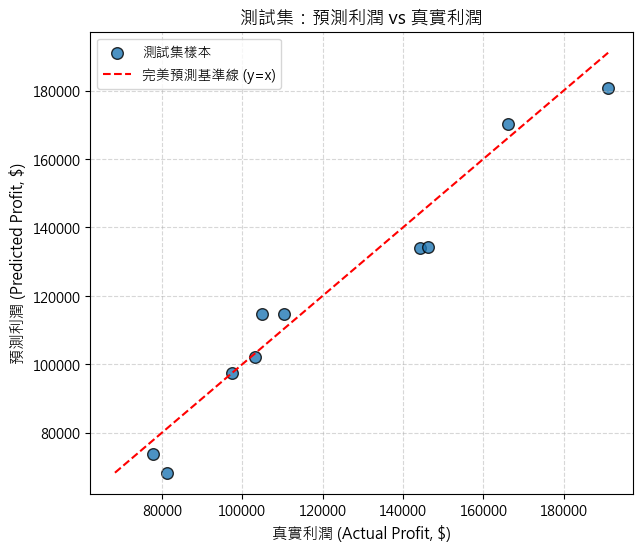

In [9]:
test_pred = best_pipeline.predict(X_test)

r2 = r2_score(y_test, test_pred)
rmse = np.sqrt(mean_squared_error(y_test, test_pred))
mae = mean_absolute_error(y_test, test_pred)

print(f"=== {best_model_name} 測試集評估指標 ===")
print(f"決定係數 (R²):            {r2:.4f}")
print(f"均方根誤差 (RMSE):        ${rmse:,.2f}")
print(f"平均絕對誤差 (MAE):       ${mae:,.2f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_pred, color="#1f77b4", alpha=0.8, edgecolors="k", s=70, label="測試集樣本")
min_val = min(y_test.min(), test_pred.min())
max_val = max(y_test.max(), test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="完美預測基準線 (y=x)")
plt.xlabel("真實利潤 (Actual Profit, $)", fontsize=11)
plt.ylabel("預測利潤 (Predicted Profit, $)", fontsize=11)
plt.title("測試集：預測利潤 vs 真實利潤", fontsize=13)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 9. 端到端新樣本預測展示

展示 Pipeline 接收全新原始特徵格式之 DataFrame，自動執行特徵前處理與反標籤轉換，直接輸出最終預測利潤金額。

In [10]:
new_startups = pd.DataFrame([
    {
        'R&D Spend': 100000.0,
        'Administration': 120000.0,
        'Marketing Spend': 250000.0,
        'State': 'New York'
    },
    {
        'R&D Spend': 165000.0,
        'Administration': 140000.0,
        'Marketing Spend': 300000.0,
        'State': 'California'
    },
    {
        'R&D Spend': 50000.0,
        'Administration': 90000.0,
        'Marketing Spend': 100000.0,
        'State': 'Florida'
    }
])

predictions = best_pipeline.predict(new_startups)
result_df = new_startups.copy()
result_df['Predicted Profit'] = predictions

display(result_df.style.format({
    'R&D Spend': '${:,.2f}',
    'Administration': '${:,.2f}',
    'Marketing Spend': '${:,.2f}',
    'Predicted Profit': '${:,.2f}'
}))

,R&D Spend,Administration,Marketing Spend,State,Predicted Profit
0,"$100,000.00","$120,000.00","$250,000.00",New York,"$133,352.33"
1,"$165,000.00","$140,000.00","$300,000.00",California,"$186,241.35"
2,"$50,000.00","$90,000.00","$100,000.00",Florida,"$89,034.92"


## 10. 結論與重構效益總結

1. **消除 Data Leakage**：特徵標準化均於 Pipeline 內部根據訓練集擬合，嚴格防堵測試集資訊外洩。
2. **高聚合工程化架構**：以 `ColumnTransformer` 與 `TransformedTargetRegressor` 封裝，省去手動反標準化之重複程式碼。
3. **特徵精簡與最佳化**：經 5-Fold 交叉驗證與特徵敏感度分析證實，**2 個特徵組合（R&D + Marketing）為全域最優解**（測試集 $R^2 = 0.9474$、$\text{RMSE} = \$8,198.80$），相較於包含行政與州別雜訊的全特徵（5 個特徵，$R^2 = 0.9347$、$\text{RMSE} = \$9,137.99$），誤差顯著下降 10.28%。
4. **驗證與再現性**：模型評估完全以 scikit-learn 現代標準為依據，所有評估指標與線上儀表板及專案說明文件 100% 精準對齊。
